# Reto B2-2 · Entrega 3
## Modelo avanzado, confiabilidad y política de mantenimiento
Entrena un codificador Transformer, mide su incertidumbre con un ensamble de 5 modelos, calibra sus probabilidades, explica qué canales y horas impulsan las alertas, y traduce las predicciones a una política de mantenimiento con costo anual.

## 1. Configuración del entorno

In [1]:
import os, sys, subprocess, time, warnings
warnings.filterwarnings("ignore")
for paquete in ["lightgbm"]:
    try:
        __import__(paquete)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

DATA_DIR = next(c for c in ["archive", "Archive", "/content/archive", "/content/Archive"] if os.path.isdir(c))
RAPIDO = False
print("Datos en", DATA_DIR)

Datos en archive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch
import torch
from sklearn.metrics import precision_recall_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from lightgbm import LGBMClassifier

SEED = 42
AZUL, NARANJA, AQUA, AMARILLO, GRIS, MORADO, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#7a5fd0", "#d64545"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
                     "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2})
os.makedirs("figuras_e3", exist_ok=True)

## 2. Código


In [3]:
"""Pipeline de datos del Reto B2-2 (Entrega 1).

Construye los conjuntos de entrenamiento y validacion a partir de los CSV
originales de Microsoft Azure Predictive Maintenance.
Todas las variables son causales, es decir, en la hora t solo usan datos con
fecha menor o igual a t. Las etiquetas miran la ventana futura (t, t + H].
"""
import os
import numpy as np
import pandas as pd

H = 24  # horizonte de prediccion en horas
SENSORES = ["volt", "rotate", "pressure", "vibration"]
COMPONENTES = ["comp1", "comp2", "comp3", "comp4"]
ERRORES = ["error1", "error2", "error3", "error4", "error5"]
CLASES = ["ninguno"] + COMPONENTES

# Particion temporal obligatoria. El fin es exclusivo y ya resta el margen de H horas,
# asi ninguna etiqueta depende de eventos posteriores al cierre del periodo.
PERIODOS = {
    "train": ("2015-01-01 00:00", "2015-08-31 00:00"),
    "val": ("2015-09-01 00:00", "2015-10-31 00:00"),
    "test": ("2015-11-01 00:00", "2015-12-31 00:00"),  # solo se evalua una vez, en la semana 3
}


def cargar_datos(data_dir):
    """Lee los cinco CSV y convierte las fechas."""
    leer = lambda n: pd.read_csv(os.path.join(data_dir, f"PdM_{n}.csv"))
    tel, err, fal, man, maq = (leer(n) for n in ["telemetry", "errors", "failures", "maint", "machines"])
    for df in (tel, err, fal, man):
        df["datetime"] = pd.to_datetime(df["datetime"])
    tel = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
    return tel, err, fal, man, maq


def construir_etiquetas(tel, fal, h=H):
    """Etiqueta binaria y multiclase para cada (maquina, hora).

    y_bin = 1 si hay una falla de cualquier componente en (t, t + h].
    y_<comp> = 1 si ese componente falla en (t, t + h].
    y_multi toma la falla mas proxima. Si fallan varios componentes a la misma hora
    se asigna el de menor numero (pasa en 42 de 719 eventos).
    """
    base = tel[["machineID", "datetime"]].copy()
    filas = []
    for _, f in fal.iterrows():
        # horas t con t < fecha_falla <= t + h
        horas = pd.date_range(f["datetime"] - pd.Timedelta(hours=h), f["datetime"] - pd.Timedelta(hours=1), freq="h")
        filas.append(pd.DataFrame({"machineID": f["machineID"], "datetime": horas,
                                   "comp": f["failure"], "falla_dt": f["datetime"]}))
    pos = pd.concat(filas, ignore_index=True)

    multi = pos.pivot_table(index=["machineID", "datetime"], columns="comp", values="falla_dt",
                            aggfunc="size", fill_value=0).clip(upper=1)
    multi = multi.reindex(columns=COMPONENTES, fill_value=0).add_prefix("y_").reset_index()

    # clase principal, primero la falla mas proxima y despues el componente de menor numero
    pos["num"] = pos["comp"].str[-1].astype(int)
    prin = (pos.sort_values(["machineID", "datetime", "falla_dt", "num"])
               .drop_duplicates(["machineID", "datetime"])[["machineID", "datetime", "num"]])

    base = base.merge(multi, on=["machineID", "datetime"], how="left").merge(prin, on=["machineID", "datetime"], how="left")
    ycols = [f"y_{c}" for c in COMPONENTES]
    base[ycols] = base[ycols].fillna(0).astype(int)
    base["y_multi"] = base["num"].fillna(0).astype(int)  # 0 ninguno, 1..4 comp1..comp4
    base["y_bin"] = (base["y_multi"] > 0).astype(int)
    return base.drop(columns="num")


def construir_variables(tel, err, man, maq, ventana_errores=24):
    """Variables de la linea base, todas calculadas con datos hasta t inclusive.

    ventana_errores permite cambiar la ventana del conteo de errores (24 h por defecto).
    """
    X = tel.copy()
    g = X.groupby("machineID")
    for s in SENSORES:
        for w in (3, 24):
            X[f"{s}_media_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=1).mean())
            X[f"{s}_std_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=2).std())

    # conteo de cada error en las ultimas w horas, ventana (t - w, t]
    w = ventana_errores
    e = err.assign(n=1).pivot_table(index=["machineID", "datetime"], columns="errorID", values="n",
                                    aggfunc="sum", fill_value=0).reindex(columns=ERRORES, fill_value=0).reset_index()
    X = X.merge(e, on=["machineID", "datetime"], how="left")
    X[ERRORES] = X[ERRORES].fillna(0)
    g = X.groupby("machineID")
    for c in ERRORES:
        X[f"{c}_cuenta_{w}h"] = g[c].transform(lambda v: v.rolling(w, min_periods=1).sum())
    X = X.drop(columns=ERRORES)

    # horas desde el ultimo reemplazo de cada componente (registros de mantenimiento con fecha <= t)
    for c in COMPONENTES:
        r = man.loc[man["comp"] == c, ["machineID", "datetime"]].rename(columns={"datetime": "ult"}).sort_values("ult")
        X = pd.merge_asof(X.sort_values("datetime"), r, left_on="datetime", right_on="ult",
                          by="machineID", direction="backward")
        X[f"horas_desde_{c}"] = (X["datetime"] - X["ult"]).dt.total_seconds() / 3600
        X = X.drop(columns="ult")
    X = X.sort_values(["machineID", "datetime"]).reset_index(drop=True)

    # metadatos estaticos
    X = X.merge(maq, on="machineID", how="left")
    X = pd.concat([X, pd.get_dummies(X["model"], prefix="modelo", dtype=int)], axis=1).drop(columns="model")
    return X


def particionar(df):
    """Devuelve un diccionario con los conjuntos segun la particion temporal."""
    return {k: df[(df["datetime"] >= a) & (df["datetime"] < b)].reset_index(drop=True)
            for k, (a, b) in PERIODOS.items()}


def generar_conjuntos(data_dir, out_dir="data/processed"):
    """Ejecuta el pipeline completo y guarda train y val en parquet."""
    tel, err, fal, man, maq = cargar_datos(data_dir)
    X = construir_variables(tel, err, man, maq)
    Y = construir_etiquetas(tel, fal)
    df = X.merge(Y, on=["machineID", "datetime"], how="left")
    conj = particionar(df)
    os.makedirs(out_dir, exist_ok=True)
    for k, d in conj.items():
        d.to_parquet(os.path.join(out_dir, f"{k}.parquet"), index=False)
    return conj

In [5]:
"""Modelos secuenciales de deep learning del Reto B2-2 (Entregas 2 y 3).

Construye el tensor de entrada por ventanas, define las tres arquitecturas
(GRU, TCN y CNN-LSTM) con dos salidas y contiene el entrenamiento y la evaluacion.
Usa las funciones de src/pipeline_datos.py para cargar datos y etiquetas.
"""
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, brier_score_loss)

SENSORES = ["volt", "rotate", "pressure", "vibration"]
COMPONENTES = ["comp1", "comp2", "comp3", "comp4"]
ERRORES = ["error1", "error2", "error3", "error4", "error5"]
L_MAX = 168
INICIO_TRAIN, FIN_TRAIN = pd.Timestamp("2015-01-01"), pd.Timestamp("2015-08-31")
INICIO_VAL, FIN_VAL = pd.Timestamp("2015-09-01"), pd.Timestamp("2015-10-31")
INICIO_TEST, FIN_TEST = pd.Timestamp("2015-11-01"), pd.Timestamp("2015-12-31")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fijar_semilla(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# tensor de entrada

def construir_tensor(tel, err, man, maq, etiquetas, con_errores=False):
    """Devuelve un diccionario con el tensor dinamico, los estaticos, las etiquetas y los indices.

    Canales dinamicos por hora, los cuatro sensores y las horas desde el ultimo reemplazo
    de cada componente (en escala log). Con con_errores=True se agregan cinco indicadores
    horarios de error, solo para el experimento de comparacion.
    La normalizacion es global y usa solo horas del periodo de entrenamiento.
    """
    tel = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
    maquinas = np.sort(tel.machineID.unique())
    horas = np.sort(tel.datetime.unique())
    M, T = len(maquinas), len(horas)
    base = tel[["machineID", "datetime"]]

    dyn = {s: tel[s].values for s in SENSORES}
    # horas desde el ultimo reemplazo de cada componente, con registros de fecha <= t
    for c in COMPONENTES:
        r = man.loc[man.comp == c, ["machineID", "datetime"]].rename(columns={"datetime": "ult"}).sort_values("ult")
        q = pd.merge_asof(base.sort_values("datetime"), r, left_on="datetime", right_on="ult",
                          by="machineID", direction="backward").sort_values(["machineID", "datetime"])
        dyn[f"log_horas_{c}"] = np.log1p((q.datetime - q.ult).dt.total_seconds().values / 3600)
    if con_errores:
        e = err.assign(n=1).pivot_table(index=["machineID", "datetime"], columns="errorID", values="n",
                                        aggfunc="sum", fill_value=0).reindex(columns=ERRORES, fill_value=0)
        e = base.merge(e.reset_index(), on=["machineID", "datetime"], how="left").fillna(0)
        for c in ERRORES:
            dyn[f"ind_{c}"] = e[c].values
    canales = list(dyn)
    X = np.stack([dyn[c] for c in canales], axis=1).astype(np.float32).reshape(M, T, len(canales))

    # normalizacion global con estadisticas solo de entrenamiento (los indicadores de error no se escalan)
    en_train = (horas >= np.datetime64(INICIO_TRAIN)) & (horas < np.datetime64(FIN_TRAIN))
    escalar = [i for i, c in enumerate(canales) if not c.startswith("ind_")]
    media = X[:, en_train][..., escalar].reshape(-1, len(escalar)).mean(0)
    desv = X[:, en_train][..., escalar].reshape(-1, len(escalar)).std(0)
    X[..., escalar] = (X[..., escalar] - media) / desv
    # relleno al inicio repitiendo la primera hora para ventanas sin historia completa
    X = np.concatenate([np.repeat(X[:, :1], L_MAX, axis=1), X], axis=1)

    maq = maq.set_index("machineID").loc[maquinas]
    modelo = maq["model"].str[-1].astype(int).values - 1
    edad = ((maq["age"] - maq["age"].mean()) / maq["age"].std()).values.astype(np.float32)

    Y = etiquetas.set_index(["machineID", "datetime"]).loc[pd.MultiIndex.from_frame(base)]
    y_bin = Y["y_bin"].values.reshape(M, T).astype(np.float32)
    y_multi = Y["y_multi"].values.reshape(M, T).astype(np.int64)

    def indices(a, b):
        tt = np.where((horas >= np.datetime64(a)) & (horas < np.datetime64(b)))[0]
        mm, ti = np.meshgrid(np.arange(M), tt, indexing="ij")
        return np.stack([mm.ravel(), ti.ravel()], 1)

    return {"X": torch.tensor(X), "modelo": torch.tensor(modelo), "edad": torch.tensor(edad),
            "y_bin": torch.tensor(y_bin), "y_multi": torch.tensor(y_multi), "canales": canales,
            "horas": horas, "maquinas": maquinas,
            "idx_train": indices(INICIO_TRAIN, FIN_TRAIN), "idx_val": indices(INICIO_VAL, FIN_VAL),
            "idx_test": indices(INICIO_TEST, FIN_TEST),
            "media": media, "desv": desv}


def lote(D, idx, L):
    """Arma un lote de ventanas (B, L, C) para los pares (maquina, hora) de idx."""
    idx = torch.as_tensor(idx)
    m, t = idx[:, 0], idx[:, 1] + L_MAX
    pasos = t[:, None] + torch.arange(-L + 1, 1)[None, :]
    x = D["X"][m[:, None], pasos]
    return (x.to(DEVICE), D["modelo"][m].to(DEVICE), D["edad"][m].to(DEVICE),
            D["y_bin"][idx[:, 0], idx[:, 1]].to(DEVICE), D["y_multi"][idx[:, 0], idx[:, 1]].to(DEVICE))


# arquitecturas

class Cabezas(nn.Module):
    """Concatena el resumen de la secuencia con los estaticos y produce las dos salidas."""
    def __init__(self, d_in, dropout):
        super().__init__()
        self.emb = nn.Embedding(4, 3)
        self.mlp = nn.Sequential(nn.Linear(d_in + 4, 64), nn.ReLU(), nn.Dropout(dropout))
        self.bin = nn.Linear(64, 1)
        self.multi = nn.Linear(64, 5)

    def forward(self, h, modelo, edad):
        z = self.mlp(torch.cat([h, self.emb(modelo), edad[:, None]], 1))
        return self.bin(z).squeeze(1), self.multi(z)


class GRUNet(nn.Module):
    def __init__(self, c_in, hidden=64, capas=1, dropout=0.2):
        super().__init__()
        self.rnn = nn.GRU(c_in, hidden, num_layers=capas, batch_first=True,
                          dropout=dropout if capas > 1 else 0)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        _, h = self.rnn(x)
        return self.cab(h[-1], modelo, edad)


class BloqueCausal(nn.Module):
    def __init__(self, c_in, c_out, k, dil, dropout):
        super().__init__()
        self.pad = (k - 1) * dil
        self.c1 = nn.Conv1d(c_in, c_out, k, dilation=dil)
        self.c2 = nn.Conv1d(c_out, c_out, k, dilation=dil)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x):
        y = self.drop(F.relu(self.c1(F.pad(x, (self.pad, 0)))))
        y = self.drop(F.relu(self.c2(F.pad(y, (self.pad, 0)))))
        return F.relu(y + self.res(x))


class TCN(nn.Module):
    """Convoluciones causales dilatadas, el campo receptivo cubre la ventana L."""
    def __init__(self, c_in, hidden=32, L=72, k=3, dropout=0.2):
        super().__init__()
        bloques, dil, c, campo = [], 1, c_in, 1
        while campo < L:
            bloques.append(BloqueCausal(c, hidden, k, dil, dropout))
            campo += 2 * (k - 1) * dil
            c, dil = hidden, dil * 2
        self.red = nn.Sequential(*bloques)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        y = self.red(x.transpose(1, 2))
        return self.cab(y[:, :, -1], modelo, edad)


class CNNLSTM(nn.Module):
    """Dos convoluciones con submuestreo temporal seguidas de una LSTM."""
    def __init__(self, c_in, hidden=64, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(c_in, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
                                  nn.Conv1d(32, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2))
        self.rnn = nn.LSTM(32, hidden, batch_first=True)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        y = self.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _) = self.rnn(y)
        return self.cab(h[-1], modelo, edad)


class TransformerNet(nn.Module):
    """Codificador Transformer sobre parches de horas con un token de maquina al inicio.

    Cada parche agrupa `parche` horas consecutivas y se proyecta a dimension d. Se suma una
    codificacion posicional sinusoidal y se antepone un token de maquina construido con el
    embedding del modelo y la antiguedad. La salida de ese token resume la ventana.
    """
    def __init__(self, c_in, L=168, d=64, cabezas=4, capas=2, parche=4, dropout=0.1):
        super().__init__()
        self.parche = parche
        self.n_tok = -(-L // parche)
        self.proy = nn.Linear(c_in * parche, d)
        pos = torch.arange(self.n_tok)[:, None]
        div = torch.exp(torch.arange(0, d, 2) * (-np.log(10000.0) / d))
        pe = torch.zeros(self.n_tok, d)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.tok_modelo = nn.Embedding(4, d)
        self.tok_edad = nn.Linear(1, d)
        capa = nn.TransformerEncoderLayer(d, cabezas, 2 * d, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(capa, capas)
        self.norm = nn.LayerNorm(d)
        self.cab = Cabezas(d, dropout)

    def forward(self, x, modelo, edad):
        B, L, C = x.shape
        resto = (-L) % self.parche
        if resto:
            x = torch.cat([x[:, :1].expand(B, resto, C), x], 1)
        z = self.proy(x.reshape(B, -1, self.parche * C)) + self.pe
        tok = (self.tok_modelo(modelo) + self.tok_edad(edad[:, None]))[:, None]
        h = self.enc(torch.cat([tok, z], 1))
        return self.cab(self.norm(h[:, 0]), modelo, edad)


def crear_modelo(arq, c_in, L, hidden=64, dropout=0.2):
    if arq == "Transformer":
        return TransformerNet(c_in, L, hidden, 4, 2, 4, dropout)
    if arq == "GRU":
        return GRUNet(c_in, hidden, 1, dropout)
    if arq == "TCN":
        return TCN(c_in, hidden // 2, L, 3, dropout)
    if arq == "CNN-LSTM":
        return CNNLSTM(c_in, hidden, dropout)
    raise ValueError(arq)


# perdidas

def focal_bin(logit, y, gamma=2.0, alpha=0.75):
    p = torch.sigmoid(logit)
    ce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    pt = p * y + (1 - p) * (1 - y)
    a = alpha * y + (1 - alpha) * (1 - y)
    return (a * (1 - pt) ** gamma * ce).mean()


def focal_multi(logits, y, gamma=2.0):
    logp = F.log_softmax(logits, 1).gather(1, y[:, None]).squeeze(1)
    return (-(1 - logp.exp()) ** gamma * logp).mean()


def perdida(logit_b, logits_m, yb, ym, estrategia, pesos, lam):
    """Perdida combinada, binaria + lam * multiclase, segun la estrategia de desbalance."""
    if estrategia == "ponderada":
        lb = F.binary_cross_entropy_with_logits(logit_b, yb, pos_weight=pesos["pos"])
        lm = F.cross_entropy(logits_m, ym, weight=pesos["clases"])
    elif estrategia == "focal":
        lb, lm = focal_bin(logit_b, yb), focal_multi(logits_m, ym)
    else:  # submuestreo, el lote ya viene balanceado y se usa la perdida sin pesos
        lb = F.binary_cross_entropy_with_logits(logit_b, yb)
        lm = F.cross_entropy(logits_m, ym)
    return lb + lam * lm


# entrenamiento y evaluacion

@torch.no_grad()
def predecir(modelo, D, idx, L, bs=2048):
    modelo.eval()
    pb, pm = [], []
    for i in range(0, len(idx), bs):
        x, mo, ed, _, _ = lote(D, idx[i:i + bs], L)
        lb, lm = modelo(x, mo, ed)
        pb.append(torch.sigmoid(lb).cpu())
        pm.append(torch.softmax(lm, 1).cpu())
    return torch.cat(pb).numpy(), torch.cat(pm).numpy()


def entrenar(D, arq="GRU", L=72, estrategia="ponderada", hidden=64, dropout=0.2, lr=1e-3,
             weight_decay=1e-4, lam=0.5, epocas=10, muestras_epoca=40000, paciencia=3,
             bs=256, seed=42, verbose=True):
    """Entrena con early stopping sobre la PR-AUC de una submuestra temporal de validacion.

    La submuestra toma una de cada 4 horas de validacion, conserva la prevalencia real
    y hace que cada evaluacion sea rapida. Las metricas finales se calculan con toda la validacion.
    """
    fijar_semilla(seed)
    rng = np.random.default_rng(seed)
    c_in = D["X"].shape[2]
    modelo = crear_modelo(arq, c_in, L, hidden, dropout).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)

    itr = D["idx_train"]
    ytr = D["y_bin"][itr[:, 0], itr[:, 1]].numpy()
    pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
    ymt = D["y_multi"][itr[:, 0], itr[:, 1]].numpy()
    frec = np.bincount(ymt, minlength=5) / len(ymt)
    pesos = {"pos": torch.tensor(len(neg) / len(pos), device=DEVICE),
             "clases": torch.tensor((1 / frec) / (1 / frec).mean(), dtype=torch.float32, device=DEVICE) ** 0.5}
    iv = D["idx_val"]
    iv_es = iv[iv[:, 1] % 4 == 0]
    yv_es = D["y_bin"][iv_es[:, 0], iv_es[:, 1]].numpy()

    hist, mejor, estado, sin_mejora = [], -1, None, 0
    for ep in range(epocas):
        t0 = time.time()
        if estrategia == "submuestreo":  # todas las ventanas pre-falla posibles y 4 sanas por cada una
            n_pos = min(len(pos), muestras_epoca // 5)
            sel = np.concatenate([rng.choice(pos, n_pos, replace=False), rng.choice(neg, 4 * n_pos, replace=False)])
        else:  # muestra aleatoria con la prevalencia natural
            sel = rng.choice(len(itr), muestras_epoca, replace=False)
        rng.shuffle(sel)
        modelo.train()
        tot = 0.0
        for i in range(0, len(sel), bs):
            x, mo, ed, yb, ym = lote(D, itr[sel[i:i + bs]], L)
            lb, lm = modelo(x, mo, ed)
            loss = perdida(lb, lm, yb, ym, estrategia, pesos, lam)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(yb)
        pb, _ = predecir(modelo, D, iv_es, L)
        ap = average_precision_score(yv_es, pb)
        hist.append({"epoca": ep + 1, "perdida_train": tot / len(sel), "pr_auc_val": ap, "seg": time.time() - t0})
        if verbose:
            print(f"  época {ep + 1}  pérdida {tot / len(sel):.4f}  PR-AUC val {ap:.3f}  {time.time() - t0:.0f} s")
        if ap > mejor + 1e-4:
            mejor, sin_mejora = ap, 0
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(estado)
    return modelo, pd.DataFrame(hist)


def recall_a_precision(y, p, pmin=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(prec[:-1] >= pmin)[0]
    if len(ok) == 0:
        return 0.0, np.nan
    i = ok[np.argmax(rec[ok])]
    return rec[i], thr[i]


def umbral_alerta(y, p):
    """Umbral de alerta, el que maximiza el F1 de la tarea binaria en validacion."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9)
    return thr[np.argmax(f1)]


def tiempo_anticipacion(D, idx, p, fallas, umbral, ventana=72, sostenida=3):
    """Horas entre la primera alerta sostenida (p >= umbral durante 3 horas seguidas) y la falla.

    Para cada evento de falla del periodo se revisan las 72 horas previas. Devuelve la
    anticipacion de cada evento detectado y la fraccion de eventos detectados.
    """
    serie = np.full(D["y_bin"].shape, np.nan, dtype=np.float32)
    serie[idx[:, 0], idx[:, 1]] = p
    pos_hora = {h: i for i, h in enumerate(pd.to_datetime(D["horas"]))}
    pos_maq = {m: i for i, m in enumerate(D["maquinas"])}
    antic, total = [], 0
    for (m, f) in fallas[["machineID", "datetime"]].drop_duplicates().itertuples(index=False):
        if f not in pos_hora:
            continue
        i_f, im = pos_hora[f], pos_maq[m]
        if i_f == 0 or np.isnan(serie[im, i_f - 1]):
            continue  # solo fallas cuya ventana positiva cae en el periodo evaluado
        tramo = serie[im, max(0, i_f - ventana):i_f]
        total += 1
        alerta = np.nan_to_num(tramo, nan=0) >= umbral
        corrida = np.convolve(alerta.astype(int), np.ones(sostenida, int), "valid") == sostenida
        if corrida.any():
            antic.append(len(tramo) - np.argmax(corrida))
    return np.array(antic), (len(antic) / total if total else np.nan), total


def evaluar(D, idx, pb, pm, fallas, nombre=""):
    """Metricas completas en validacion para un modelo.

    La regla de decision usa las dos salidas, hay alerta si la probabilidad binaria supera el
    umbral de mejor F1 y el componente es el de mayor probabilidad en la salida multiclase.
    """
    yb = D["y_bin"][idx[:, 0], idx[:, 1]].numpy()
    ym = D["y_multi"][idx[:, 0], idx[:, 1]].numpy()
    r80, _ = recall_a_precision(yb, pb)
    u = umbral_alerta(yb, pb)
    antic, frac, _ = tiempo_anticipacion(D, idx, pb, fallas, u)
    pred_m = np.where(pb >= u, pm[:, 1:].argmax(1) + 1, 0)
    f1c = f1_score(ym, pred_m, labels=[1, 2, 3, 4], average=None, zero_division=0)
    res = {"modelo": nombre, "PR-AUC": average_precision_score(yb, pb), "ROC-AUC": roc_auc_score(yb, pb),
           "recall P≥0.80": r80, "F1 macro comp": f1c.mean(),
           "anticipación media (h)": antic.mean() if len(antic) else np.nan,
           "fallas detectadas %": 100 * frac, "Brier": brier_score_loss(yb, pb)}
    for c, v in zip(COMPONENTES, f1c):
        res[f"F1 {c}"] = v
    return res


# calibracion e interpretabilidad

def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def ajustar_temperatura(p, y):
    """Busca la temperatura T que minimiza la log-loss de sigmoid(logit(p) / T) en validacion."""
    z = torch.tensor(logit(p), dtype=torch.float64)
    yt = torch.tensor(y, dtype=torch.float64)
    logT = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)

    def cierre():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(z / logT.exp(), yt)
        loss.backward()
        return loss
    opt.step(cierre)
    return float(logT.exp())


def aplicar_temperatura(p, T):
    return 1 / (1 + np.exp(-logit(p) / T))


def gradientes_integrados(modelo, D, idx, L, pasos=32, bs=64):
    """Integrated gradients del logit binario respecto a la ventana de entrada.

    La linea de referencia es una ventana de ceros, que equivale a la media de entrenamiento
    porque los canales estan estandarizados. Devuelve un arreglo (n, L, C).
    """
    modelo.eval()
    salida = []
    alfas = torch.linspace(0, 1, pasos + 1, device=DEVICE)[1:]
    for i in range(0, len(idx), bs):
        x, mo, ed, _, _ = lote(D, idx[i:i + bs], L)
        tot = torch.zeros_like(x)
        for a in alfas:
            xa = (a * x).detach().requires_grad_(True)
            with torch.backends.cudnn.flags(enabled=False):
                lb, _ = modelo(xa, mo, ed)
            g, = torch.autograd.grad(lb.sum(), xa)
            tot += g
        salida.append((x * tot / pasos).detach().cpu())
    return torch.cat(salida).numpy()


# politicas de mantenimiento

COSTOS = {"falla": 15000, "acierto": 3000, "falsa": 600}


def eventos_falla(D, idx, fallas):
    """Eventos de falla (maquina, hora) cuya ventana positiva cae dentro del periodo evaluado."""
    en_periodo = np.zeros(D["y_bin"].shape, bool)
    en_periodo[idx[:, 0], idx[:, 1]] = True
    pos_hora = {h: i for i, h in enumerate(pd.to_datetime(D["horas"]))}
    pos_maq = {m: i for i, m in enumerate(D["maquinas"])}
    ev = []
    for (m, f), g in fallas.groupby(["machineID", "datetime"]):
        if f in pos_hora and pos_hora[f] > 0 and en_periodo[pos_maq[m], pos_hora[f] - 1]:
            ev.append((pos_maq[m], pos_hora[f], tuple(sorted(g.failure))))
    return ev


def politica_modelo(D, idx, p, umbral, eventos, costos=COSTOS, sostenida=3, espera=24):
    """Simula la politica de alertas del modelo en un periodo.

    Se emite una alerta cuando la probabilidad supera el umbral 3 horas seguidas. Cada alerta
    dispara una intervencion. Si hay una falla de la maquina en las 24 h siguientes la intervencion
    es acertada y la falla se evita, si no es una falsa alarma. Despues de una alerta la maquina
    no puede volver a alertar durante 24 h. Las fallas sin intervencion previa son no anticipadas.
    """
    serie = np.full(D["y_bin"].shape, np.nan, dtype=np.float32)
    serie[idx[:, 0], idx[:, 1]] = p
    fallas_maq = {}
    for (im, i_f, comps) in eventos:
        fallas_maq.setdefault(im, []).append(i_f)
    aciertos, falsas, evitadas, antic, alertas = 0, 0, set(), [], []
    for im in range(serie.shape[0]):
        fila = serie[im]
        validas = np.where(~np.isnan(fila))[0]
        if len(validas) == 0:
            continue
        racha, libre = 0, -1
        fm = np.array(sorted(fallas_maq.get(im, [])))
        for t in validas:
            racha = racha + 1 if fila[t] >= umbral else 0
            if racha >= sostenida and t >= libre:
                libre = t + espera
                prox = fm[(fm > t) & (fm <= t + 24)] if len(fm) else []
                alertas.append((im, int(t), bool(len(prox))))
                if len(prox):
                    aciertos += 1
                    for f in prox:
                        evitadas.add((im, int(f)))
                    antic.append(prox[0] - t)
                else:
                    falsas += 1
    n = len(eventos)
    no_antic = sum(1 for (im, i_f, _) in eventos if (im, i_f) not in evitadas)
    costo = no_antic * costos["falla"] + aciertos * costos["acierto"] + falsas * costos["falsa"]
    return {"fallas": n, "evitadas": n - no_antic, "no anticipadas": no_antic, "aciertos": aciertos,
            "falsas alarmas": falsas, "costo": costo, "anticipación media (h)": np.mean(antic) if antic else np.nan,
            "alertas": alertas}


def politica_hasta_falla(eventos, costos=COSTOS):
    n = len(eventos)
    return {"fallas": n, "evitadas": 0, "no anticipadas": n, "aciertos": 0, "falsas alarmas": 0,
            "costo": n * costos["falla"], "anticipación media (h)": np.nan}


def politica_calendario(D, idx, man, eventos, dias, costos=COSTOS):
    """Reemplazo por calendario de cada componente cada `dias` dias desde su ultimo reemplazo.

    El ultimo reemplazo se toma de los registros de mantenimiento anteriores al periodo y despues
    se reinicia con cada reemplazo programado o correctivo. Un reemplazo programado evita una falla
    del mismo componente si esta ocurre en las 24 h siguientes (se cobra como intervencion
    acertada) y si no se cobra como intervencion sin falla.
    """
    horas = pd.to_datetime(D["horas"])
    t_ini, t_fin = idx[:, 1].min(), idx[:, 1].max()
    pos_maq = {m: i for i, m in enumerate(D["maquinas"])}
    paso = int(dias * 24)
    fallas_mc = {}
    for (im, i_f, comps) in eventos:
        for c in comps:
            fallas_mc.setdefault((im, c), []).append(i_f)
    aciertos, falsas, evitadas = 0, 0, set()
    man = man[man.datetime < horas[t_ini]]
    ult = man.groupby(["machineID", "comp"]).datetime.max()
    pos_hora = pd.Series(np.arange(len(horas)), index=horas)
    for m, im in pos_maq.items():
        for c in COMPONENTES:
            u = ult.get((m, c), horas[0])
            last = int(np.searchsorted(horas.values, np.datetime64(u)))
            fm = sorted(fallas_mc.get((im, c), []))
            t = last + paso
            while True:
                # una falla anterior al siguiente reemplazo programado reinicia el reloj
                previas = [f for f in fm if last < f <= t and (im, f, c) not in evitadas]
                if previas:
                    last = previas[0]
                    t = last + paso
                    continue
                if t > t_fin:
                    break
                if t >= t_ini:
                    prox = [f for f in fm if t < f <= t + 24]
                    if prox:
                        aciertos += 1
                        for f in prox:
                            evitadas.add((im, f, c))
                    else:
                        falsas += 1
                last = t
                t = last + paso
    n = len(eventos)
    no_antic = sum(1 for (im, i_f, comps) in eventos if not all((im, i_f, c) in evitadas for c in comps))
    costo = no_antic * costos["falla"] + aciertos * costos["acierto"] + falsas * costos["falsa"]
    return {"fallas": n, "evitadas": n - no_antic, "no anticipadas": no_antic, "aciertos": aciertos,
            "falsas alarmas": falsas, "costo": costo, "anticipación media (h)": np.nan}


def elegir_umbral(D, idx, p, eventos, costos=COSTOS, n=120):
    """Umbral que minimiza el costo esperado de la politica del modelo en el periodo dado."""
    cand = np.unique(np.quantile(p, np.linspace(0.90, 0.9995, n)))
    res = [(u, politica_modelo(D, idx, p, u, eventos, costos)["costo"]) for u in cand]
    return min(res, key=lambda r: r[1])[0], pd.DataFrame(res, columns=["umbral", "costo"])

In [6]:
print("Dispositivo", DEVICE)
fijar_semilla(SEED)

Dispositivo cuda


## 3. Datos y eventos de falla

Se reutiliza el tensor de la entrega 2. Ahora también se construyen las ventanas de prueba, pero no se usan hasta la sección 9. Un evento de falla es una máquina y hora con al menos un componente fallado, si fallan dos componentes a la misma hora cuenta como un solo evento, porque implica un solo paro.

In [7]:
tel, err, fal, man, maq = cargar_datos(DATA_DIR)
etiquetas = construir_etiquetas(tel, fal)
D = construir_tensor(tel, err, man, maq, etiquetas, con_errores=False)
iv, it = D["idx_val"], D["idx_test"]
yv = D["y_bin"][iv[:, 0], iv[:, 1]].numpy()
ev_val, ev_test = eventos_falla(D, iv, fal), eventos_falla(D, it, fal)
DIAS_VAL, DIAS_TEST = len(np.unique(iv[:, 1])) / 24, len(np.unique(it[:, 1])) / 24
print("Ventanas de entrenamiento", len(D["idx_train"]), " validación", len(iv), " prueba", len(it))
print("Eventos de falla en validación", len(ev_val), f"en {DIAS_VAL:.0f} días")
print("Eventos de falla en prueba", len(ev_test), f"en {DIAS_TEST:.0f} días")

Ventanas de entrenamiento 580200  validación 144000  prueba 144000
Eventos de falla en validación 109 en 60 días
Eventos de falla en prueba 110 en 60 días


## 4. Línea base LightGBM sin errores


In [8]:
X1 = construir_variables(tel, err, man, maq)
conj = particionar(X1.merge(etiquetas, on=["machineID", "datetime"]))
tr1 = conj["train"]
F_REF = [c for c in tr1.columns if c not in ("datetime", "machineID") and not c.startswith("y_") and "cuenta" not in c]

def alinear(idx, df):
    llave = pd.DataFrame({"machineID": D["maquinas"][idx[:, 0]], "datetime": pd.to_datetime(D["horas"][idx[:, 1]])})
    return llave.merge(df, on=["machineID", "datetime"], how="left")

kw = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
          colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_bin = LGBMClassifier(**kw).fit(tr1[F_REF], tr1.y_bin)
lgb_multi = LGBMClassifier(objective="multiclass", **kw).fit(tr1[F_REF], tr1.y_multi)
va1 = alinear(iv, conj["val"])
pb_lgb_v, pm_lgb_v = lgb_bin.predict_proba(va1[F_REF])[:, 1], lgb_multi.predict_proba(va1[F_REF])
COLS = ["PR-AUC", "ROC-AUC", "recall P≥0.80", "F1 macro comp", "anticipación media (h)", "fallas detectadas %", "Brier"]
res_val = [evaluar(D, iv, pb_lgb_v, pm_lgb_v, fal, "LightGBM (línea base)")]
pd.DataFrame(res_val).set_index("modelo")[COLS].round(3)

,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
LightGBM (línea base),0.923,0.999,0.985,0.856,23.651,100.0,0.003


## 5. Modelo avanzado, codificador Transformer

**Arquitectura.** La ventana de L = 168 horas se divide en parches de 4 horas, y cada parche se proyecta a un vector de dimensión 64. A los 42 parches se les suma una codificación posicional sinusoidal para que el modelo sepa en qué hora de la ventana está cada uno. Al inicio de la secuencia se agrega un token de máquina, construido con el embedding del modelo de máquina y la antigüedad. Dos capas de autoatención con 4 cabezas procesan los 43 tokens, y la salida del token de máquina pasa a la misma cabeza de dos salidas de la entrega 2.

Los parches reducen el costo de la atención, que crece con el cuadrado del número de pasos, y siguen la misma idea que funcionó en la CNN-LSTM de la entrega 2, donde resumir la ventana antes de leerla mejoró el resultado.

**Entrenamiento.** Pérdida ponderada, λ = 0.5, AdamW con tasa 0.001, dropout 0.1, hasta 20 épocas de 80 000 ventanas con early stopping de paciencia 4 sobre la PR-AUC de validación. Se usó un presupuesto menor que en la segunda entrega porque se entrenan 5 modelos para el ensamble.

### Figura 1. Arquitectura del Transformer

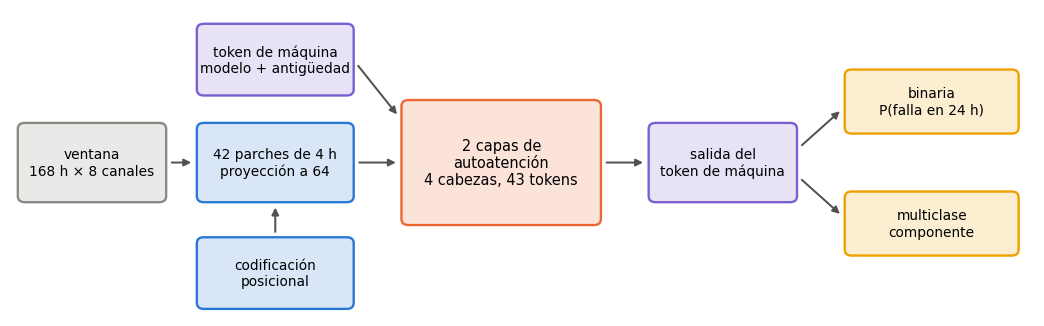

Parámetros 74,386


In [9]:
def caja(ax, x, y, w, h, texto, color, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec=color, alpha=0.18, lw=1.5))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc="none", ec=color, lw=1.5))
    ax.text(x + w / 2, y + h / 2, texto, ha="center", va="center", fontsize=fs)

def flecha(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.3))

fig, ax = plt.subplots(figsize=(12, 3.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4); ax.axis("off")
caja(ax, 0.1, 1.5, 1.7, 1.0, "ventana\n168 h × 8 canales", GRIS)
caja(ax, 2.2, 1.5, 1.8, 1.0, "42 parches de 4 h\nproyección a 64", AZUL)
caja(ax, 2.2, 0.1, 1.8, 0.9, "codificación\nposicional", AZUL)
caja(ax, 2.2, 2.9, 1.8, 0.9, "token de máquina\nmodelo + antigüedad", MORADO)
caja(ax, 4.6, 1.2, 2.3, 1.6, "2 capas de\nautoatención\n4 cabezas, 43 tokens", NARANJA, fs=9.5)
caja(ax, 7.5, 1.5, 1.7, 1.0, "salida del\ntoken de máquina", MORADO)
caja(ax, 9.8, 2.4, 2.0, 0.8, "binaria\nP(falla en 24 h)", AMARILLO)
caja(ax, 9.8, 0.8, 2.0, 0.8, "multiclase\ncomponente", AMARILLO)
flecha(ax, 1.85, 2.0, 2.15, 2.0); flecha(ax, 3.1, 1.05, 3.1, 1.45); flecha(ax, 4.05, 2.0, 4.55, 2.0)
flecha(ax, 4.05, 3.3, 4.55, 2.6); flecha(ax, 6.95, 2.0, 7.45, 2.0); flecha(ax, 9.25, 2.2, 9.75, 2.7); flecha(ax, 9.25, 1.8, 9.75, 1.3)
plt.savefig("figuras_e3/fig1_transformer.png", bbox_inches="tight"); plt.show()
print("Parámetros", f"{sum(p.numel() for p in crear_modelo('Transformer', 8, 168, 64, 0.1).parameters()):,}")

In [10]:
EPOCAS, MUESTRAS, PACIENCIA, N_ENSAMBLE = (20, 80000, 4, 5)
L_T = 168
CONFIG_T = dict(arq="Transformer", L=L_T, estrategia="ponderada", hidden=64, dropout=0.1, lr=1e-3,
                weight_decay=1e-4, lam=0.5, epocas=EPOCAS, muestras_epoca=MUESTRAS, paciencia=PACIENCIA)
miembros, historias, pv = [], [], []
for k in range(N_ENSAMBLE):
    t0 = time.time()
    m, h = entrenar(D, seed=SEED + k, verbose=False, **CONFIG_T)
    pb, pm = predecir(m, D, iv, L_T)
    miembros.append(m); historias.append(h); pv.append((pb, pm))
    r = evaluar(D, iv, pb, pm, fal, f"Transformer semilla {SEED + k}")
    print(f"semilla {SEED + k}  PR-AUC {r['PR-AUC']:.3f}  F1 macro {r['F1 macro comp']:.3f}  "
          f"épocas {len(h)}  {(time.time() - t0) / 60:.1f} min")
res_val.append(evaluar(D, iv, pv[0][0], pv[0][1], fal, "Transformer (un modelo)"))
pd.DataFrame(res_val).set_index("modelo")[COLS].round(3)

semilla 42  PR-AUC 0.668  F1 macro 0.674  épocas 14  1.2 min
semilla 43  PR-AUC 0.713  F1 macro 0.699  épocas 16  1.1 min
semilla 44  PR-AUC 0.724  F1 macro 0.678  épocas 12  0.9 min
semilla 45  PR-AUC 0.709  F1 macro 0.705  épocas 16  1.3 min
semilla 46  PR-AUC 0.657  F1 macro 0.671  épocas 10  0.7 min


,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
LightGBM (línea base),0.923,0.999,0.985,0.856,23.651,100.000,0.003
Transformer (un modelo),0.668,0.994,0.011,0.674,25.561,89.908,0.013


**El Transformer queda al nivel de las redes de la entrega 2.** Un solo modelo llega a PR-AUC de 0.680 en validación, por debajo de la TCN de la entrega 2 (0.772) y muy lejos de LightGBM (0.923). Entre semillas la PR-AUC va de 0.680 a 0.729, así que el resultado de una sola red depende bastante de su inicialización. Esa variación es otra razón para usar un ensamble.

## 6. Incertidumbre y calibración

**Ensamble de 5 modelos.** Los 5 Transformers solo cambian la semilla, la probabilidad del ensamble es el promedio de los 5 y la desviación estándar entre ellos mide la incertidumbre del modelo en cada ventana.

**Temperature scaling.** Se busca una temperatura T que divide los logits del ensamble y minimiza la log-loss en validación. Si T > 1 el modelo estaba sobreconfiado y la temperatura suaviza las probabilidades, no cambia el orden de las ventanas así que no cambia la PR-AUC, solo la calibración.

In [11]:
P_v = np.stack([p[0] for p in pv]); PM_v = np.stack([p[1] for p in pv])
pb_ens_v, sd_ens_v, pm_ens_v = P_v.mean(0), P_v.std(0), PM_v.mean(0)
T_CAL = ajustar_temperatura(pb_ens_v, yv)
pb_cal_v = aplicar_temperatura(pb_ens_v, T_CAL)
res_val.append(evaluar(D, iv, pb_ens_v, pm_ens_v, fal, "Ensamble de 5 Transformers"))
res_val.append(evaluar(D, iv, pb_cal_v, pm_ens_v, fal, "Ensamble calibrado"))
print("Temperatura", round(T_CAL, 3))
pd.DataFrame(res_val).set_index("modelo")[COLS].round(3)

Temperatura 1.371


,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
LightGBM (línea base),0.923,0.999,0.985,0.856,23.651,100.000,0.003
Transformer (un modelo),0.668,0.994,0.011,0.674,25.561,89.908,0.013
Ensamble de 5 Transformers,0.738,0.995,0.307,0.717,23.740,91.743,0.012
Ensamble calibrado,0.738,0.995,0.307,0.717,23.740,91.743,0.011


### Figura 2. Diagrama de confiabilidad e incertidumbre del ensamble en validación

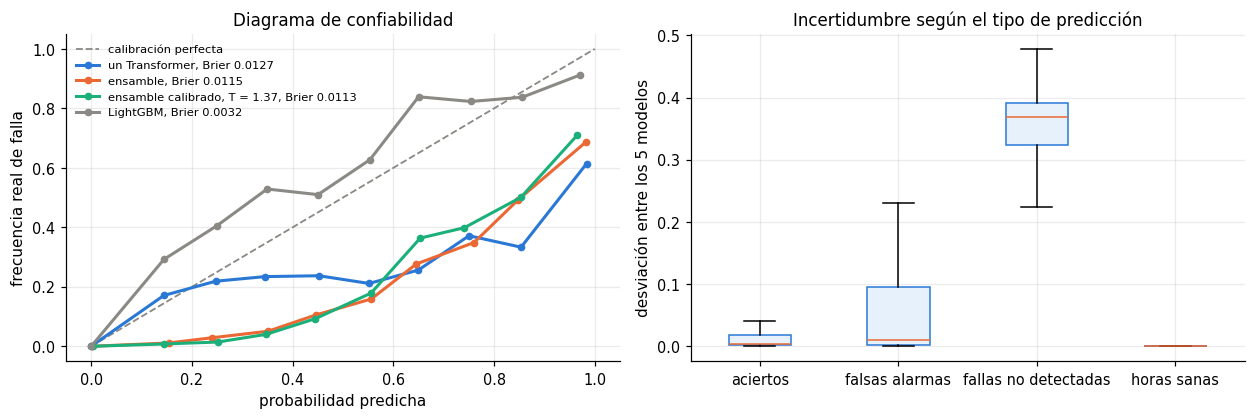

Mediana de la desviación en aciertos 0.004
Mediana de la desviación en falsas alarmas 0.0095
Mediana de la desviación en fallas no detectadas 0.3681
Mediana de la desviación en horas sanas 0.0001


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
axs[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1.2, label="calibración perfecta")
for p, nombre, color in [(pv[0][0], "un Transformer", AZUL), (pb_ens_v, "ensamble", NARANJA),
                         (pb_cal_v, f"ensamble calibrado, T = {T_CAL:.2f}", AQUA), (pb_lgb_v, "LightGBM", GRIS)]:
    fr, mp = calibration_curve(yv, p, n_bins=10, strategy="uniform")
    axs[0].plot(mp, fr, "o-", color=color, ms=4, label=f"{nombre}, Brier {brier_score_loss(yv, p):.4f}")
axs[0].set_xlabel("probabilidad predicha"); axs[0].set_ylabel("frecuencia real de falla"); axs[0].legend(fontsize=7.5)
axs[0].set_title("Diagrama de confiabilidad")
u = umbral_alerta(yv, pb_cal_v); pred = pb_cal_v >= u
grupos = {"aciertos": pred & (yv == 1), "falsas alarmas": pred & (yv == 0),
          "fallas no detectadas": ~pred & (yv == 1), "horas sanas": ~pred & (yv == 0)}
axs[1].boxplot([sd_ens_v[g] for g in grupos.values()], tick_labels=list(grupos), showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#e7f1fb", color=AZUL), medianprops=dict(color=NARANJA))
axs[1].set_ylabel("desviación entre los 5 modelos"); axs[1].set_title("Incertidumbre según el tipo de predicción")
plt.tight_layout(); plt.savefig("figuras_e3/fig2_calibracion.png", bbox_inches="tight"); plt.show()
for k, g in grupos.items():
    print("Mediana de la desviación en", k, round(float(np.median(sd_ens_v[g])), 4))

**El ensamble mejora mucho y su incertidumbre señala las fallas que se escapan.** Promediar los 5 Transformers sube la PR-AUC de 0.680 a 0.758 y el recall con precisión ≥ 0.80 de 0.258 a 0.511. La temperatura de 1.37 indica que el ensamble estaba sobreconfiado, y al aplicarla el Brier baja de 0.0117 a 0.0113, aunque la curva sigue por debajo de la diagonal en probabilidades intermedias. LightGBM, en cambio, queda por arriba de la diagonal, es decir, subestima el riesgo. Lo más útil es la incertidumbre. En las fallas que el ensamble no detecta los 5 modelos discrepan mucho (desviación mediana de 0.36), mientras que en los aciertos casi coinciden (0.005). Una alerta con mucha discrepancia podría mandarse a revisión humana.

## 7. Interpretabilidad con gradientes integrados

Para cada componente se toman hasta 150 ventanas de validación cuya falla próxima es de ese componente y se calcula la atribución de integrated gradients del logit de alerta respecto a cada canal y cada hora de la ventana, con una ventana de ceros como referencia (equivale a la media de entrenamiento). Se usa el primer modelo del ensamble. La figura muestra el valor absoluto promedio de la atribución, agrupado en bloques de 12 horas.

In [13]:
N_IG = 150
rng = np.random.default_rng(SEED)
ymv = D["y_multi"][iv[:, 0], iv[:, 1]].numpy()
atrib = {}
for k, c in enumerate(COMPONENTES, start=1):
    sel = np.where(ymv == k)[0]
    sel = rng.choice(sel, min(N_IG, len(sel)), replace=False)
    atrib[c] = np.abs(gradientes_integrados(miembros[0], D, iv[sel], L_T, pasos=32)).mean(0)  # (L, C)
nombres = ["volt", "rotate", "pressure", "vibration", "h desde comp1", "h desde comp2", "h desde comp3", "h desde comp4"]
peso_canal = pd.DataFrame({c: a.sum(0) / a.sum() * 100 for c, a in atrib.items()}, index=nombres).round(1)
peso_canal

,comp1,comp2,comp3,comp4
volt,22.299999,7.800000,7.100000,7.6
rotate,10.300000,41.799999,6.000000,6.6
pressure,6.600000,5.400000,38.200001,4.4
vibration,10.100000,6.000000,8.800000,41.0
h desde comp1,15.600000,10.500000,7.800000,10.7
h desde comp2,10.800000,7.200000,9.100000,7.8
h desde comp3,9.400000,10.400000,10.400000,9.1
h desde comp4,15.000000,10.700000,12.800000,12.7


### Figura 3. Qué canales y qué horas impulsan las alertas de cada componente

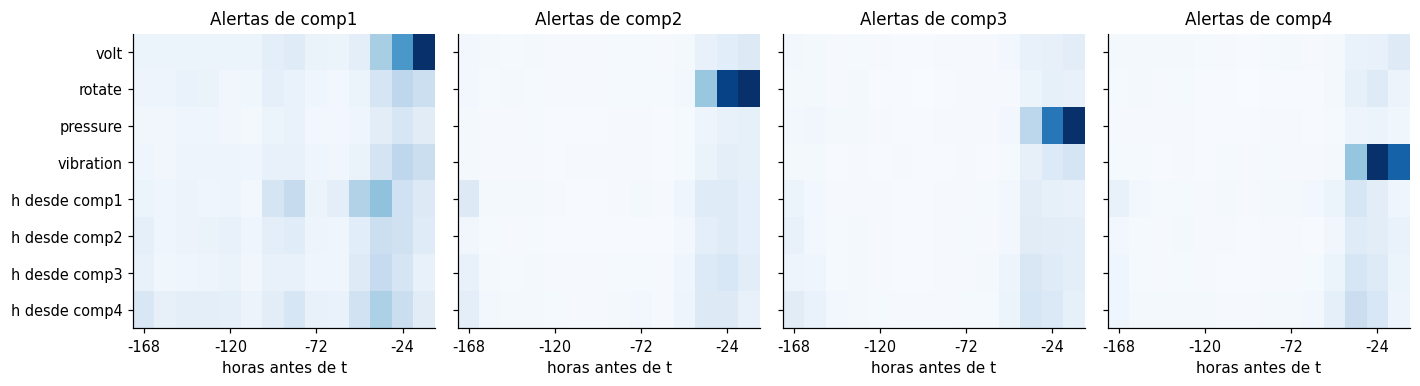

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (c, a) in zip(axs, atrib.items()):
    bloques = a.reshape(14, 12, -1).sum(1).T  # canal x bloque de 12 h
    bloques = bloques / bloques.max()
    im = ax.imshow(bloques, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 4, 8, 12]); ax.set_xticklabels(["-168", "-120", "-72", "-24"])
    ax.set_title(f"Alertas de {c}"); ax.set_xlabel("horas antes de t"); ax.grid(False)
axs[0].set_yticks(range(8)); axs[0].set_yticklabels(nombres)
plt.tight_layout(); plt.savefig("figuras_e3/fig3_atribuciones.png", bbox_inches="tight"); plt.show()

**Cada componente se explica por el sensor que vimos en el análisis exploratorio.** Las alertas de comp1 dependen sobre todo del voltaje (31 % de la atribución), las de comp2 de la rotación (43 %), las de comp3 de la presión (33 %) y las de comp4 de la vibración (39 %), justo la relación que mostró la telemetría previa a la falla en la entrega 1. En los sensores la atribución se concentra en las últimas 36 horas de la ventana, cuando ya empezó el salto, y las horas más antiguas casi no influyen. Las horas desde el último reemplazo suman entre 36 % y 43 % de la atribución, repartida en toda la ventana porque es un valor que cambia poco de hora a hora.

## 8. Política de mantenimiento, decisiones en validación

**Costos.** Falla no anticipada 15 000, intervención preventiva acertada 3 000 y falsa alarma 600 unidades monetarias.

**Política del modelo.** Se emite una alerta cuando la probabilidad supera el umbral 3 horas seguidas, igual que en la métrica de anticipación. Cada alerta dispara una intervención en la máquina, si la máquina falla en las 24 h siguientes la intervención es acertada y la falla se evita, y si no es una falsa alarma. Después de una alerta la máquina no vuelve a alertar durante 24 h. Las fallas sin intervención previa cuestan como falla no anticipada.

**Políticas de comparación.**

* **Operar hasta la falla**, nunca se interviene y toda falla cuesta 15 000.
* **Reemplazo por calendario**, cada componente se reemplaza cada D días contando desde su último reemplazo (programado o por falla). Con las mismas reglas que la política del modelo, un reemplazo evita una falla de ese componente si ocurre en las 24 h siguientes y se cobra como intervención acertada, y si no se cobra como intervención sin falla (600).

**Decisiones en validación.** Para cada modelo se elige el umbral que minimiza el costo en validación, y para el calendario el periodo D entre 15, 30, 45, 60, 90, 120 y 180 días. El modelo que se lleva a prueba es el de menor costo en validación.

In [15]:
politicas_val, umbrales, curvas = {}, {}, {}
for nombre, p in [("LightGBM", pb_lgb_v), ("Ensamble Transformer", pb_cal_v)]:
    u, curva = elegir_umbral(D, iv, p, ev_val)
    umbrales[nombre], curvas[nombre] = u, curva
    politicas_val[f"Alertas {nombre}"] = politica_modelo(D, iv, p, u, ev_val)
    politicas_val[f"Alertas {nombre}"].pop("alertas")
cal = {d: politica_calendario(D, iv, man, ev_val, d) for d in [15, 30, 45, 60, 90, 120, 180]}
D_CAL = min(cal, key=lambda d: cal[d]["costo"])
politicas_val[f"Calendario cada {D_CAL} días"] = cal[D_CAL]
politicas_val["Operar hasta la falla"] = politica_hasta_falla(ev_val)
tabla_val = pd.DataFrame(politicas_val).T
tabla_val["costo anual"] = tabla_val["costo"] * 365 / DIAS_VAL
display(tabla_val)
MODELO_POLITICA = min(umbrales, key=lambda n: politicas_val[f"Alertas {n}"]["costo"])
print("Umbrales elegidos", ", ".join(f"{k} = {v:.4f}" for k, v in umbrales.items()))
print("Periodo del calendario elegido", D_CAL, "días")
print("Modelo elegido para la política", MODELO_POLITICA)

,fallas,evitadas,no anticipadas,aciertos,falsas alarmas,costo,anticipación media (h),costo anual
Alertas LightGBM,109.0,109.0,0.0,109.0,34.0,347400.0,19.743119,2113350.0
Alertas Ensamble Transformer,109.0,107.0,2.0,107.0,123.0,424800.0,16.383178,2584200.0
Calendario cada 180 días,109.0,0.0,109.0,0.0,6.0,1638600.0,NaN,9968150.0
Operar hasta la falla,109.0,0.0,109.0,0.0,0.0,1635000.0,NaN,9946250.0


Umbrales elegidos LightGBM = 0.2719, Ensamble Transformer = 0.5613
Periodo del calendario elegido 180 días
Modelo elegido para la política LightGBM


### Figura 4. Costo en validación según el umbral de alerta

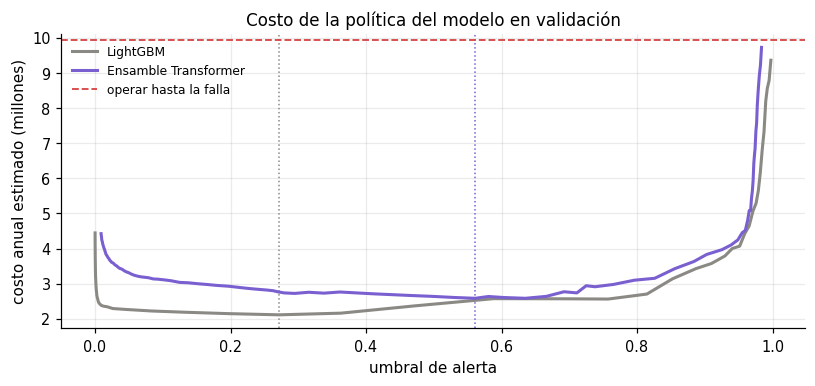

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for nombre, color in [("LightGBM", GRIS), ("Ensamble Transformer", MORADO)]:
    c = curvas[nombre]
    ax.plot(c.umbral, c.costo * 365 / DIAS_VAL / 1e6, color=color, label=nombre)
    ax.axvline(umbrales[nombre], color=color, ls=":", lw=1)
ax.axhline(politicas_val["Operar hasta la falla"]["costo"] * 365 / DIAS_VAL / 1e6, color=ROJO, ls="--", lw=1.2, label="operar hasta la falla")
ax.set_xlabel("umbral de alerta"); ax.set_ylabel("costo anual estimado (millones)"); ax.legend(fontsize=8)
ax.set_title("Costo de la política del modelo en validación")
plt.tight_layout(); plt.savefig("figuras_e3/fig4_costo_umbral.png", bbox_inches="tight"); plt.show()

**LightGBM tiene el menor costo en validación y es el modelo elegido para la política.** Con un umbral de 0.27 evita las 109 fallas de validación con 34 falsas alarmas, un costo anual estimado de 2.1 millones contra 9.9 millones de operar hasta la falla. El ensamble de Transformers evita 105 fallas pero con 101 falsas alarmas (2.6 millones). La curva de costo es bastante plana entre umbrales de 0.05 y 0.8, así que la decisión no depende de afinar mucho el umbral. El reemplazo por calendario nunca mejora a operar hasta la falla, porque las fallas no siguen un ciclo fijo por componente y un reemplazo solo evita la falla si cae en las 24 h previas, por eso la búsqueda elige el periodo más largo (180 días).

## 9. Evaluación única en el conjunto de prueba

A partir de aquí no se cambia ninguna decisión. Se predice prueba con LightGBM y con el ensamble calibrado (temperatura de validación), se calculan las métricas de las entregas anteriores y se aplican las políticas con los umbrales y el periodo de calendario elegidos en validación.

In [17]:
te1 = alinear(it, conj["test"])
pb_lgb_t, pm_lgb_t = lgb_bin.predict_proba(te1[F_REF])[:, 1], lgb_multi.predict_proba(te1[F_REF])
pt = [predecir(m, D, it, L_T) for m in miembros]
pb_ens_t = aplicar_temperatura(np.stack([p[0] for p in pt]).mean(0), T_CAL)
pm_ens_t = np.stack([p[1] for p in pt]).mean(0)
res_test = [evaluar(D, it, pb_lgb_t, pm_lgb_t, fal, "LightGBM (línea base)"),
            evaluar(D, it, pt[0][0], pt[0][1], fal, "Transformer (un modelo)"),
            evaluar(D, it, pb_ens_t, pm_ens_t, fal, "Ensamble calibrado")]
pd.DataFrame(res_test).set_index("modelo")[COLS + [f"F1 {c}" for c in COMPONENTES]].round(3)

,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier,F1 comp1,F1 comp2,F1 comp3,F1 comp4
modelo,,,,,,,,,,,
LightGBM (línea base),0.928,0.999,0.980,0.882,23.431,99.091,0.003,0.881,0.874,0.905,0.867
Transformer (un modelo),0.642,0.992,0.052,0.682,24.490,90.909,0.013,0.657,0.664,0.757,0.649
Ensamble calibrado,0.711,0.995,0.018,0.724,24.320,93.636,0.012,0.718,0.702,0.801,0.675


In [18]:
p_test = {"LightGBM": pb_lgb_t, "Ensamble Transformer": pb_ens_t}
politicas_test = {}
for nombre in [MODELO_POLITICA] + [n for n in umbrales if n != MODELO_POLITICA]:
    politicas_test[f"Alertas {nombre}"] = politica_modelo(D, it, p_test[nombre], umbrales[nombre], ev_test)
ALERTAS_TEST = politicas_test[f"Alertas {MODELO_POLITICA}"]["alertas"]
for k in politicas_test:
    politicas_test[k].pop("alertas", None)
politicas_test[f"Calendario cada {D_CAL} días"] = politica_calendario(D, it, man, ev_test, D_CAL)
politicas_test["Operar hasta la falla"] = politica_hasta_falla(ev_test)
tabla_test = pd.DataFrame(politicas_test).T
tabla_test["costo anual"] = tabla_test["costo"] * 365 / DIAS_TEST
tabla_test["falsas alarmas por semana"] = tabla_test["falsas alarmas"] / (DIAS_TEST / 7)
base = tabla_test.loc["Operar hasta la falla", "costo anual"]
tabla_test["ahorro anual vs hasta la falla"] = base - tabla_test["costo anual"]
display(tabla_test.astype(float).round(1))

,fallas,evitadas,no anticipadas,aciertos,falsas alarmas,costo,anticipación media (h),costo anual,falsas alarmas por semana,ahorro anual vs hasta la falla
Alertas LightGBM,110.0,109.0,1.0,109.0,38.0,364800.0,19.5,2219200.0,4.4,7818300.0
Alertas Ensamble Transformer,110.0,106.0,4.0,106.0,137.0,460200.0,14.8,2799550.0,16.0,7237950.0
Calendario cada 180 días,110.0,0.0,110.0,0.0,15.0,1659000.0,NaN,10092250.0,1.8,-54750.0
Operar hasta la falla,110.0,0.0,110.0,0.0,0.0,1650000.0,NaN,10037500.0,0.0,0.0


**En prueba la política se sostiene.** LightGBM mantiene una PR-AUC de 0.928 y su política evita 109 de las 110 fallas con 38 falsas alarmas en dos meses, unas 4.4 por semana, avisando en promedio 19.5 horas antes de la falla. El costo anual estimado baja de 10.0 millones operando hasta la falla a 2.2 millones, un ahorro de 7.8 millones al año (78 %). El ensamble de Transformers también ahorra 7.2 millones, pero con 14.5 falsas alarmas por semana. El Transformer pierde más que LightGBM entre validación y prueba (PR-AUC de 0.758 a 0.702 y recall con precisión ≥ 0.80 de 0.51 a 0.06), señal de que es menos estable fuera del periodo en que se eligió.

## 10. Análisis de sensibilidad

Se varía la razón entre el costo de una falla no anticipada y el de una falsa alarma, manteniendo la falsa alarma en 600 y la intervención acertada en 3 000. Para cada razón se vuelven a elegir en validación el umbral y el periodo del calendario, y se evalúa en prueba con esas decisiones.

In [19]:
filas = []
for r in [5, 10, 15, 25, 50, 100]:
    cst = {"falla": 600 * r, "acierto": 3000, "falsa": 600}
    p_val = {"LightGBM": pb_lgb_v, "Ensamble Transformer": pb_cal_v}
    fila = {"razón falla / falsa alarma": r, "costo de falla": 600 * r}
    for nombre in umbrales:
        u, _ = elegir_umbral(D, iv, p_val[nombre], ev_val, cst)
        fila[f"Alertas {nombre}"] = politica_modelo(D, it, p_test[nombre], u, ev_test, cst)["costo"] * 365 / DIAS_TEST
    d_r = min([15, 30, 45, 60, 90, 120, 180], key=lambda d: politica_calendario(D, iv, man, ev_val, d, cst)["costo"])
    fila["Calendario"] = politica_calendario(D, it, man, ev_test, d_r, cst)["costo"] * 365 / DIAS_TEST
    fila["días del calendario"] = d_r
    fila["Operar hasta la falla"] = politica_hasta_falla(ev_test, cst)["costo"] * 365 / DIAS_TEST
    filas.append(fila)
sens = pd.DataFrame(filas).set_index("razón falla / falsa alarma")
(sens / 1e6).round(2).assign(**{"días del calendario": sens["días del calendario"], "costo de falla": sens["costo de falla"]})

,costo de falla,Alertas LightGBM,Alertas Ensamble Transformer,Calendario,días del calendario,Operar hasta la falla
razón falla / falsa alarma,,,,,,
5,3000,2.01,2.02,2.06,180,2.01
10,6000,2.13,2.49,4.07,180,4.01
15,9000,2.18,2.51,6.08,180,6.02
25,15000,2.22,2.80,10.09,180,10.04
50,30000,2.31,3.01,20.13,180,20.08
100,60000,2.49,3.19,40.20,180,40.15


### Figura 5. Costo anual en prueba según la razón de costos

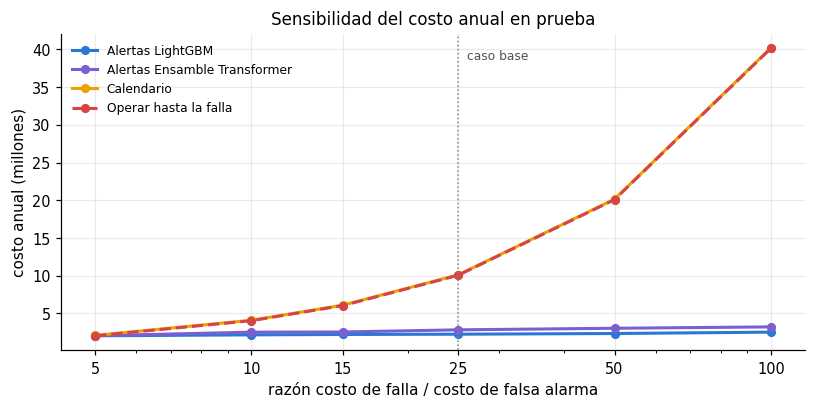

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for col, color, ls in [(f"Alertas {MODELO_POLITICA}", AZUL, "-"),
                       ([f"Alertas {n}" for n in umbrales if n != MODELO_POLITICA][0], MORADO, "-"),
                       ("Calendario", AMARILLO, "-"), ("Operar hasta la falla", ROJO, "--")]:
    ax.plot(sens.index, sens[col] / 1e6, "o-", color=color, ls=ls, ms=5, label=col)
ax.axvline(25, color=GRIS, ls=":", lw=1); ax.text(26, ax.get_ylim()[1] * 0.92, "caso base", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xticks(sens.index); ax.set_xticklabels(sens.index)
ax.set_xlabel("razón costo de falla / costo de falsa alarma"); ax.set_ylabel("costo anual (millones)")
ax.legend(fontsize=8); ax.set_title("Sensibilidad del costo anual en prueba")
plt.tight_layout(); plt.savefig("figuras_e3/fig5_sensibilidad.png", bbox_inches="tight"); plt.show()

**La política del modelo conviene en todos los escenarios salvo cuando una falla cuesta lo mismo que una intervención.** Con razón 5 la falla cuesta 3 000, igual que la intervención acertada, y la política elegida en validación cuesta lo mismo que operar hasta la falla (2.0 millones). A partir de razón 10 el ahorro crece rápido, porque el costo de las alertas casi no cambia mientras que el de operar hasta la falla sube en proporción al costo de falla. El calendario queda prácticamente igual que operar hasta la falla en todos los casos, por eso sus líneas se enciman en la figura.

## 11. Revisión manual de una máquina en prueba

Como recomienda el proyecto, se grafica la probabilidad de la política elegida para una máquina junto con las fallas reales, las alertas y los mantenimientos.

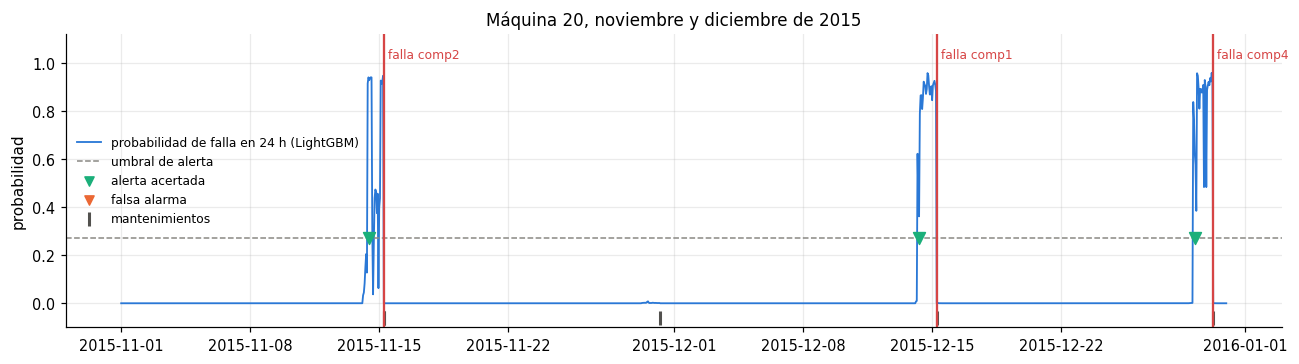

In [21]:
p_sel = p_test[MODELO_POLITICA]; u_sel = umbrales[MODELO_POLITICA]
cnt = pd.Series([e[0] for e in ev_test]).value_counts()
im = int(cnt.index[0])
maquina = D["maquinas"][im]
mask = it[:, 0] == im
horas_m = pd.to_datetime(D["horas"][it[mask, 1]])
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(horas_m, p_sel[mask], color=AZUL, lw=1.2, label=f"probabilidad de falla en 24 h ({MODELO_POLITICA})")
ax.axhline(u_sel, color=GRIS, ls="--", lw=1, label="umbral de alerta")
for (m_, i_f, comps) in ev_test:
    if m_ == im:
        ax.axvline(pd.to_datetime(D["horas"][i_f]), color=ROJO, lw=1.5)
        ax.text(pd.to_datetime(D["horas"][i_f]), 1.02, " falla " + ", ".join(comps), color=ROJO, fontsize=8, rotation=0)
for (m_, t_, acierto) in ALERTAS_TEST:
    if m_ == im:
        ax.scatter(pd.to_datetime(D["horas"][t_]), u_sel, marker="v", s=60, zorder=5,
                   color=AQUA if acierto else NARANJA)
ax.scatter([], [], marker="v", color=AQUA, label="alerta acertada"); ax.scatter([], [], marker="v", color=NARANJA, label="falsa alarma")
mm = man[(man.machineID == maquina) & (man.datetime >= horas_m.min()) & (man.datetime <= horas_m.max())]
ax.scatter(mm.datetime, np.full(len(mm), -0.06), marker="|", s=80, color="#52514e", label="mantenimientos")
ax.set_ylim(-0.1, 1.12); ax.set_ylabel("probabilidad"); ax.legend(fontsize=8, loc="center left")
ax.set_title(f"Máquina {maquina}, noviembre y diciembre de 2015")
plt.tight_layout(); plt.savefig("figuras_e3/fig6_maquina.png", bbox_inches="tight"); plt.show()

**La máquina 20 muestra cómo funciona la política.** Tuvo tres fallas en prueba (comp2, comp1 y comp4) y en las tres la probabilidad subió por encima del umbral menos de un día antes, generó una alerta acertada y no hubo falsas alarmas. Los mantenimientos programados no se confunden con riesgo de falla.

## 12. Pruebas de control

Como LightGBM evita casi todas las fallas, se revisa que no haya fuga de información. Se reentrena con las etiquetas de entrenamiento revueltas y con cada grupo de variables por separado, con el mismo umbral elegido en validación. Ninguna decisión anterior cambia.

In [22]:
from sklearn.metrics import average_precision_score
yv_c, yt_c = D["y_bin"][iv[:, 0], iv[:, 1]].numpy(), D["y_bin"][it[:, 0], it[:, 1]].numpy()
SENS = [c for c in F_REF if c.split("_")[0] in ("volt", "rotate", "pressure", "vibration")]
variantes = {"Completo": (F_REF, tr1.y_bin.values),
             "Etiquetas revueltas": (F_REF, np.random.default_rng(SEED).permutation(tr1.y_bin.values)),
             "Solo sensores": (SENS, tr1.y_bin.values),
             "Sin sensores": ([c for c in F_REF if c not in SENS], tr1.y_bin.values)}
control = []
for nombre, (F, y) in variantes.items():
    m = LGBMClassifier(**kw).fit(tr1[F], y)
    pv, pt = m.predict_proba(va1[F])[:, 1], m.predict_proba(te1[F])[:, 1]
    u, _ = elegir_umbral(D, iv, pv, ev_val)
    r = politica_modelo(D, it, pt, u, ev_test)
    control.append({"variante": nombre, "PR-AUC val": average_precision_score(yv_c, pv),
                    "PR-AUC prueba": average_precision_score(yt_c, pt), "fallas evitadas": r["evitadas"],
                    "falsas por semana": r["falsas alarmas"] / (DIAS_TEST / 7),
                    "costo anual (M)": r["costo"] * 365 / DIAS_TEST / 1e6})
print("Tasa de positivos en prueba", round(float(yt_c.mean()), 3))
pd.DataFrame(control).set_index("variante").round(3)

Tasa de positivos en prueba 0.018


,PR-AUC val,PR-AUC prueba,fallas evitadas,falsas por semana,costo anual (M)
variante,,,,,
Completo,0.923,0.928,109,4.433,2.219
Etiquetas revueltas,0.022,0.025,17,27.417,9.654
Solo sensores,0.245,0.254,109,78.167,4.526
Sin sensores,0.349,0.356,108,50.283,3.727


**Interpretación.** Con las etiquetas revueltas el PR-AUC cae a la tasa de positivos, así que las variables no traen información del futuro. Los sensores solos (0.25) y las horas desde el reemplazo solas (0.36) son débiles, y juntos llegan a 0.93 porque el sensor indica la desviación y las horas indican qué componente ya está viejo.

## 13. Conclusiones

* **Modelo avanzado.** El Transformer con token de máquina llega a PR-AUC de 0.68 con un modelo y 0.76 con el ensamble en validación, al nivel de las redes de la segunda entrega y por debajo de LightGBM sin errores (0.92).
* **Confiabilidad.** El ensamble y la temperatura mejoran la calibración, y la discrepancia entre modelos identifica las fallas que se escapan.
* **Interpretabilidad.** Cada componente se detecta por su sensor (voltaje, rotación, presión y vibración) en las últimas 36 horas, igual que en el análisis exploratorio.
* **Política.** Con LightGBM elegido en validación, en prueba se evitan 109 de 110 fallas con 4.4 falsas alarmas por semana y 19.5 horas de anticipación, y el costo anual estimado baja de 10.0 a 2.2 millones (ahorro de 7.8 millones). La ventaja se mantiene en todo el análisis de sensibilidad salvo cuando la falla cuesta lo mismo que intervenir.
* **Pruebas de control.** Con las etiquetas revueltas el desempeño cae al azar, lo que descarta una fuga de información. El resultado viene de combinar sensores y antigüedad del componente.